# 12 — Fatores associados ao desfecho desfavorável do tratamento (A4)

**Pergunta central da pesquisa:** quais fatores sociodemográficos, clínicos e operacionais estão associados ao
abandono ou óbito no tratamento da tuberculose em Ilhéus e Itabuna (2014–2024)?

- **Desfecho desfavorável** = abandono, abandono primário, óbito por TB ou falência; **favorável** = cura.
  Transferência, óbito por outras causas, TB-DR, mudança de esquema e casos sem encerramento ficam fora.
- **Base:** casos novos residentes (coorte do notebook 09).
- **Método:** razão de chances bruta (uma variável por vez) e ajustada por **regressão logística múltipla**.
  Variáveis sim/não com "ignorado" entram como "sim" x "não"; escolaridade e raça ignoradas viram categoria própria
  para não perder casos.
- Um segundo modelo usa só **abandono x cura**, que é a pergunta das reuniões.

O TDO não entra no modelo principal: o notebook 10 mostrou que em Itabuna o campo ficou vazio em 2016–2020.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path('..', 'src').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf
import tb_utils as tb

tb.estilo()
df = tb.carrega_base()
ii = tb.residentes_ii(df)
base = ii[ii['coorte_casos_novos'] & ii['desfavoravel'].notna()].copy()
print(f'Casos novos com desfecho favorável ou desfavorável: {len(base)}')
print(f"Desfavorável: {int(base['desfavoravel'].sum())} ({100 * base['desfavoravel'].mean():.1f}%)")
base['desfecho'].value_counts()

Casos novos com desfecho favorável ou desfavorável: 2400
Desfavorável: 433 (18.0%)


desfecho
Cura            1967
Abandono         322
Óbito por TB     110
Falência           1
Name: count, dtype: int64

## 1. Preparação das variáveis

In [2]:
def sim_nao(s):
    return s.map({1.0: 'Sim', 0.0: 'Não'})

m = pd.DataFrame(index=base.index)
m['desfavoravel'] = base['desfavoravel']
m['abandono'] = base['abandono']
m['cidade'] = base['cidade']
m['sexo'] = base['sexo'].where(base['sexo'].isin(['Masculino', 'Feminino']))
m['idade'] = base['faixa_etaria_ampla'].astype('object')
m['raca'] = np.select([base['raca'].isin(['Preta', 'Parda']), base['raca'].isin(['Branca', 'Amarela', 'Indígena'])],
                      ['Preta/Parda', 'Branca/Amarela/Indígena'], default='Ignorada')
m['escolaridade'] = base['escolaridade_grupo'].fillna('Ignorada')
m.loc[base['escolaridade'].eq('Não se aplica'), 'escolaridade'] = np.nan
m['forma'] = np.where(base['forma'] == 'Extrapulmonar', 'Extrapulmonar', 'Pulmonar')
m['hiv'] = base['hiv'].map({'Positivo': 'Positivo', 'Negativo': 'Negativo'}).fillna('Não testado / em andamento')
for v in ['alcoolismo', 'drogas_ilicitas', 'tabagismo', 'diabetes', 'doenca_mental', 'situacao_rua',
          'privado_liberdade', 'beneficiario_governo']:
    m[v] = sim_nao(base[v])
m['periodo'] = pd.cut(base['ano_diag'], bins=[2013, 2019, 2021, 2024], labels=['2014-2019', '2020-2021', '2022-2024']).astype('object')

ROTULOS = {'cidade': 'Cidade', 'sexo': 'Sexo', 'idade': 'Faixa etária', 'raca': 'Raça/cor', 'escolaridade': 'Escolaridade',
           'forma': 'Forma clínica', 'hiv': 'HIV', 'alcoolismo': 'Alcoolismo', 'drogas_ilicitas': 'Drogas ilícitas',
           'tabagismo': 'Tabagismo', 'diabetes': 'Diabetes', 'doenca_mental': 'Doença mental',
           'situacao_rua': 'Situação de rua', 'privado_liberdade': 'Privado de liberdade',
           'beneficiario_governo': 'Beneficiário de programa social', 'periodo': 'Período'}
REF = {'cidade': 'Ilhéus', 'sexo': 'Feminino', 'idade': '30-44', 'raca': 'Branca/Amarela/Indígena',
       'escolaridade': 'Média/Alta', 'forma': 'Pulmonar', 'hiv': 'Negativo', 'periodo': '2014-2019'}
for v in ROTULOS:
    REF.setdefault(v, 'Não')

# Tabela descritiva: n e % desfavorável por categoria
desc = []
for v, nome in ROTULOS.items():
    t = m.groupby(v)['desfavoravel'].agg(['size', 'mean'])
    for cat, row in t.iterrows():
        desc.append({'variável': nome, 'categoria': cat, 'n': int(row['size']), '% desfavorável': 100 * row['mean']})
desc = pd.DataFrame(desc)
desc.round(1)

,variável,categoria,n,% desfavorável
0,Cidade,Ilhéus,1024,14.9
1,Cidade,Itabuna,1376,20.3
2,Sexo,Feminino,779,13.9
3,Sexo,Masculino,1621,20.0
4,Faixa etária,0-14,57,8.8
5,Faixa etária,15-29,754,17.0
6,Faixa etária,30-44,685,19.9
7,Faixa etária,45-59,514,19.1
8,Faixa etária,60+,390,16.9
9,Raça/cor,Branca/Amarela/Indígena,181,16.6


## 2. Razão de chances bruta e ajustada

In [3]:
def termo(v):
    return f"C({v}, Treatment(reference='{REF[v]}'))"

def tabela_or(modelo, variaveis):
    params, ic, p = modelo.params, modelo.conf_int(), modelo.pvalues
    linhas = []
    for v in variaveis:
        prefixo = termo(v)
        for nome in params.index:
            if nome.startswith(prefixo):
                cat = nome.split('[T.')[1].rstrip(']')
                linhas.append({'variável': ROTULOS[v], 'categoria': cat, 'ref.': REF[v], 'OR': np.exp(params[nome]),
                               'IC95% inf': np.exp(ic.loc[nome, 0]), 'IC95% sup': np.exp(ic.loc[nome, 1]), 'p': p[nome]})
    return pd.DataFrame(linhas)

variaveis = list(ROTULOS)
dados = m.dropna(subset=variaveis + ['desfavoravel'])
print(f'Casos com todas as variáveis preenchidas (modelo ajustado): {len(dados)} de {len(m)} '
      f'({100 * len(dados) / len(m):.1f}%)')

brutas = []
for v in variaveis:
    sub = m.dropna(subset=[v, 'desfavoravel'])
    mod = smf.logit(f'desfavoravel ~ {termo(v)}', data=sub).fit(disp=False)
    brutas.append(tabela_or(mod, [v]).assign(n=len(sub)))
brutas = pd.concat(brutas, ignore_index=True)

formula = 'desfavoravel ~ ' + ' + '.join(termo(v) for v in variaveis)
mod_aj = smf.logit(formula, data=dados).fit(disp=False)
ajust = tabela_or(mod_aj, variaveis)

res = brutas.merge(ajust, on=['variável', 'categoria', 'ref.'], suffixes=(' bruto', ' ajustado'))
res = res[['variável', 'categoria', 'ref.', 'n', 'OR bruto', 'IC95% inf bruto', 'IC95% sup bruto', 'p bruto',
           'OR ajustado', 'IC95% inf ajustado', 'IC95% sup ajustado', 'p ajustado']]
res.to_csv(tb.PROCESSED / 'regressao_desfecho_desfavoravel.csv', index=False)
print(f'Pseudo-R² de McFadden: {mod_aj.prsquared:.3f}; AIC: {mod_aj.aic:.0f}')
res.round(3)

Casos com todas as variáveis preenchidas (modelo ajustado): 1626 de 2400 (67.8%)


Pseudo-R² de McFadden: 0.101; AIC: 1396


,variável,categoria,ref.,n,OR bruto,IC95% inf bruto,IC95% sup bruto,p bruto,OR ajustado,IC95% inf ajustado,IC95% sup ajustado,p ajustado
0,Cidade,Itabuna,Ilhéus,2400,1.454,1.172,1.805,0.001,2.051,1.510,2.784,0.000
1,Sexo,Masculino,Feminino,2400,1.558,1.230,1.974,0.000,1.347,0.976,1.861,0.070
2,Faixa etária,0-14,30-44,2400,0.388,0.152,0.990,0.048,0.265,0.034,2.052,0.204
3,Faixa etária,15-29,30-44,2400,0.825,0.632,1.078,0.159,0.957,0.658,1.392,0.818
4,Faixa etária,45-59,30-44,2400,0.951,0.712,1.270,0.733,0.899,0.611,1.321,0.587
5,Faixa etária,60+,30-44,2400,0.822,0.594,1.138,0.237,0.828,0.538,1.275,0.392
6,Raça/cor,Ignorada,Branca/Amarela/Indígena,2400,1.212,0.717,2.049,0.473,0.837,0.358,1.958,0.682
7,Raça/cor,Preta/Parda,Branca/Amarela/Indígena,2400,1.108,0.737,1.666,0.623,0.702,0.424,1.162,0.169
8,Escolaridade,Baixa,Média/Alta,2376,1.731,1.334,2.246,0.000,1.263,0.908,1.755,0.165
9,Escolaridade,Ignorada,Média/Alta,2376,1.520,1.130,2.043,0.006,1.163,0.760,1.781,0.486


In [4]:
from sklearn.metrics import roc_auc_score
auc = roc_auc_score(dados['desfavoravel'], mod_aj.predict(dados))
print(f'Área sob a curva ROC do modelo ajustado: {auc:.3f}')

Área sob a curva ROC do modelo ajustado: 0.718


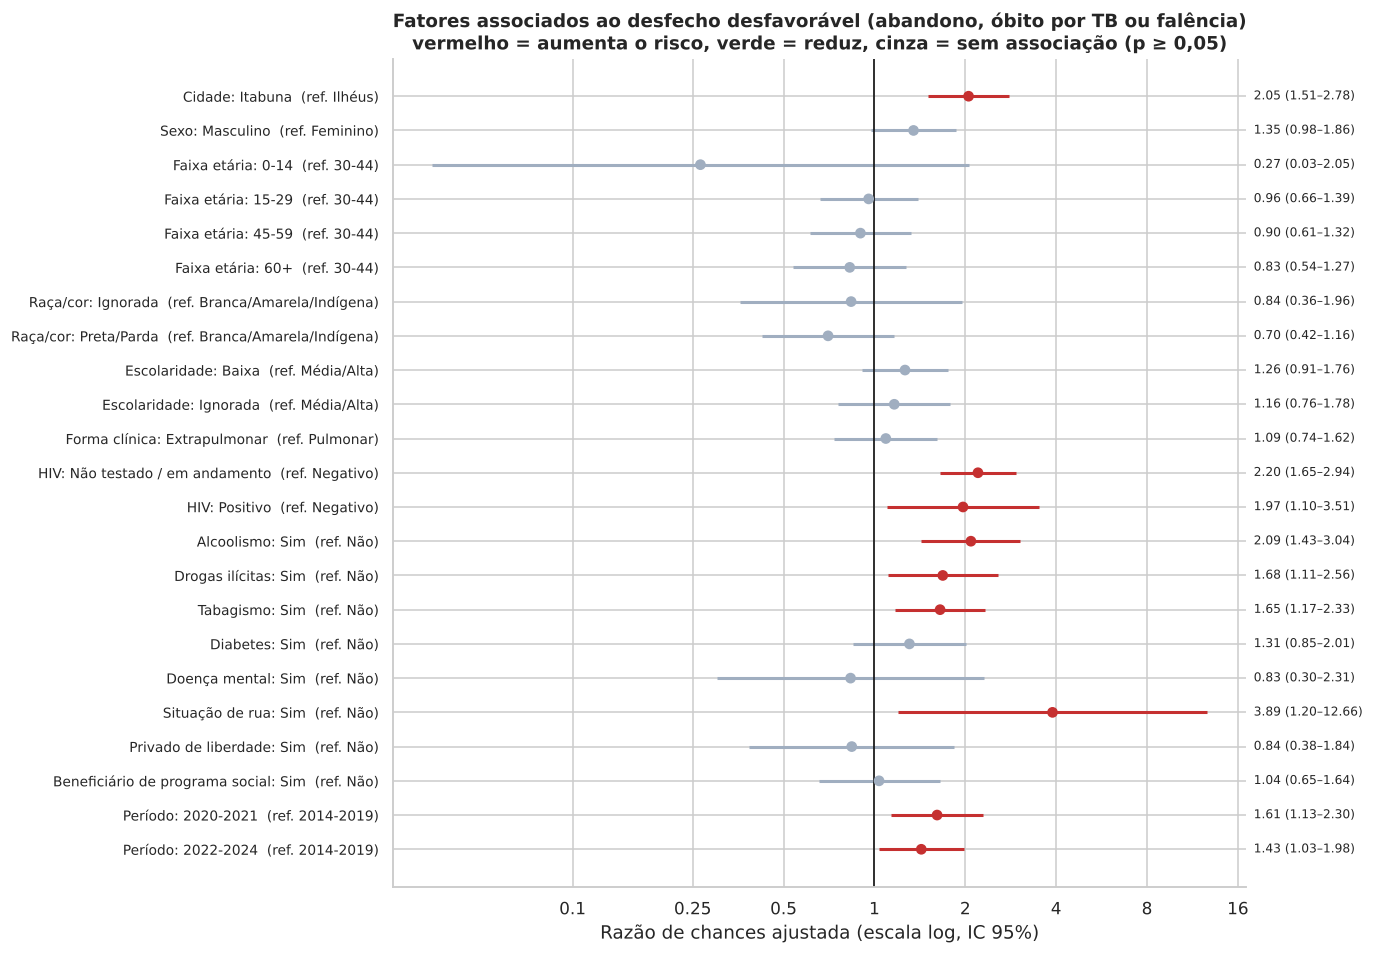

In [5]:
def forest(tab, titulo, nome_fig):
    t = tab.iloc[::-1].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(10, 0.36 * len(t) + 1.5))
    y = np.arange(len(t))
    sig = t['p'] < 0.05
    cor = np.where(sig, np.where(t['OR'] > 1, '#c53030', '#2f855a'), '#a0aec0')
    ax.hlines(y, t['IC95% inf'], t['IC95% sup'], color=cor, lw=2)
    ax.scatter(t['OR'], y, color=cor, zorder=3, s=36)
    ax.axvline(1, color='black', lw=1)
    ax.set_xscale('log'); ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 4, 8, 16]); ax.minorticks_off()
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set_yticks(y); ax.set_yticklabels(t['variável'] + ': ' + t['categoria'] + '  (ref. ' + t['ref.'] + ')', fontsize=9)
    for yi, (o, lo, hi) in enumerate(zip(t['OR'], t['IC95% inf'], t['IC95% sup'])):
        ax.text(ax.get_xlim()[1], yi, f'  {o:.2f} ({lo:.2f}–{hi:.2f})', va='center', fontsize=8)
    ax.set_xlabel('Razão de chances ajustada (escala log, IC 95%)'); ax.set_title(titulo)
    tb.salva_fig(fig, nome_fig); plt.show()

forest(ajust, 'Fatores associados ao desfecho desfavorável (abandono, óbito por TB ou falência)\n'
       'vermelho = aumenta o risco, verde = reduz, cinza = sem associação (p ≥ 0,05)', '12_forest_desfavoravel')

## 3. Só abandono x cura

n = 1562; abandonos = 218


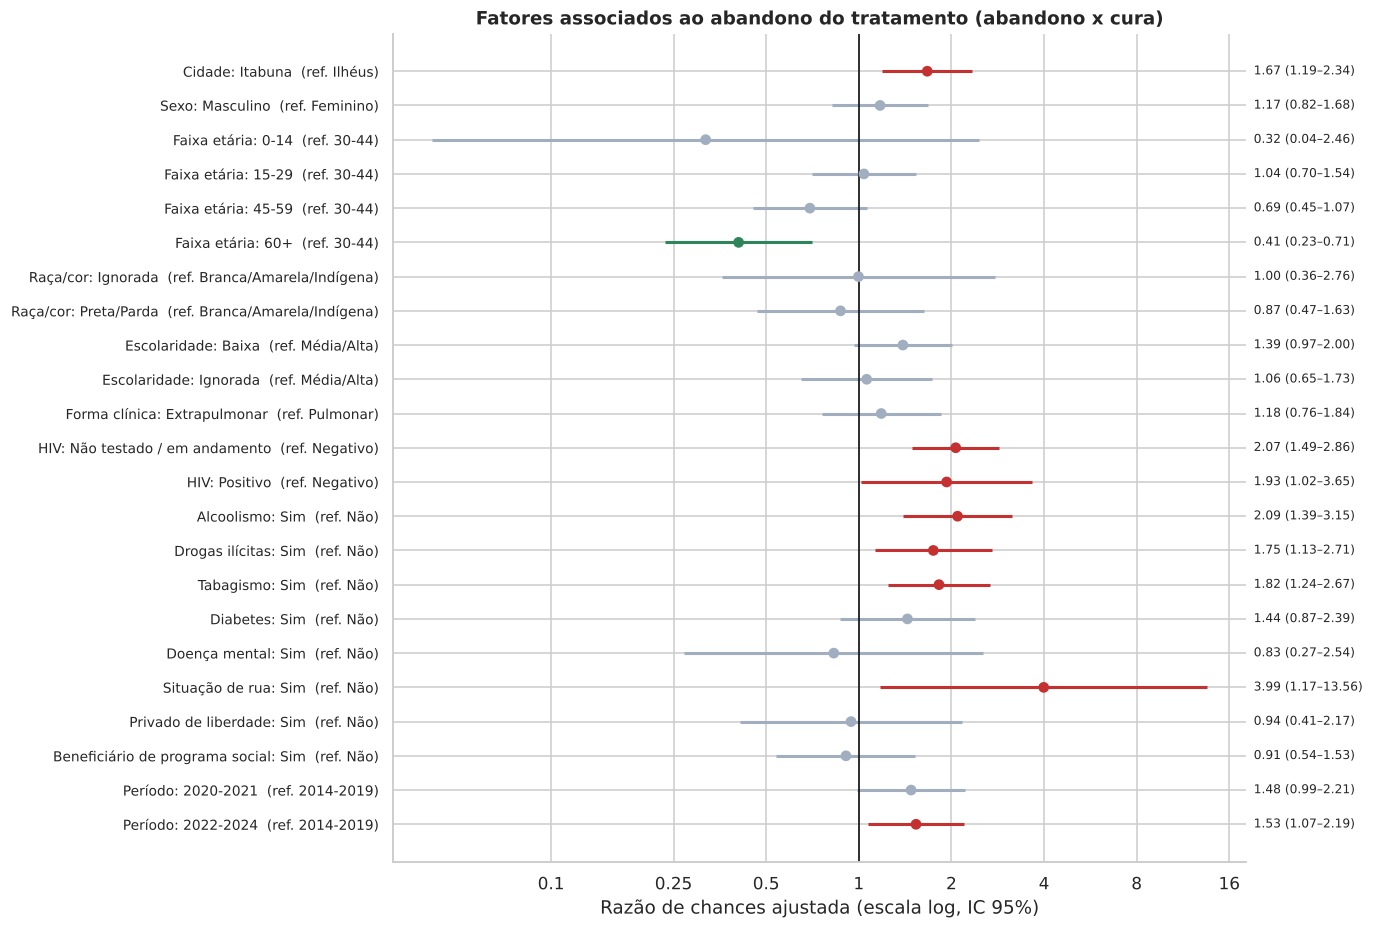

,variável,categoria,ref.,OR,IC95% inf,IC95% sup,p
0,Cidade,Itabuna,Ilhéus,1.669,1.191,2.339,0.003
1,Sexo,Masculino,Feminino,1.173,0.817,1.683,0.387
2,Faixa etária,0-14,30-44,0.318,0.041,2.461,0.272
3,Faixa etária,15-29,30-44,1.039,0.702,1.539,0.847
4,Faixa etária,45-59,30-44,0.694,0.452,1.065,0.095
5,Faixa etária,60+,30-44,0.407,0.234,0.706,0.001
6,Raça/cor,Ignorada,Branca/Amarela/Indígena,0.998,0.360,2.765,0.997
7,Raça/cor,Preta/Parda,Branca/Amarela/Indígena,0.872,0.468,1.627,0.667
8,Escolaridade,Baixa,Média/Alta,1.391,0.966,2.003,0.076
9,Escolaridade,Ignorada,Média/Alta,1.061,0.651,1.728,0.813


In [6]:
dados_ab = dados[base.loc[dados.index, 'desfecho'].isin(['Cura', 'Abandono', 'Abandono primário'])]
mod_ab = smf.logit(formula.replace('desfavoravel', 'abandono'), data=dados_ab).fit(disp=False)
ajust_ab = tabela_or(mod_ab, variaveis)
print(f'n = {len(dados_ab)}; abandonos = {int(dados_ab["abandono"].sum())}')
forest(ajust_ab, 'Fatores associados ao abandono do tratamento (abandono x cura)', '12_forest_abandono')
ajust_ab.round(3)

## 4. Os fatores pesam igual nas duas cidades?

Mesmo modelo rodado separadamente em cada cidade (sem a variável cidade). Mostramos os fatores principais.

In [7]:
var_cid = [v for v in variaveis if v != 'cidade']
form_cid = 'desfavoravel ~ ' + ' + '.join(termo(v) for v in var_cid)
por_cidade = []
for cidade in ['Ilhéus', 'Itabuna']:
    d = dados[dados['cidade'] == cidade]
    mod = smf.logit(form_cid, data=d).fit(disp=False, maxiter=200)
    por_cidade.append(tabela_or(mod, var_cid).assign(cidade=cidade, n=len(d)))
por_cidade = pd.concat(por_cidade)
chave = ['Alcoolismo', 'Drogas ilícitas', 'Situação de rua', 'Privado de liberdade', 'HIV', 'Sexo', 'Escolaridade', 'Faixa etária', 'Período']
(por_cidade[por_cidade['variável'].isin(chave)]
 .pivot_table(index=['variável', 'categoria'], columns='cidade', values=['OR', 'p']).round(3))

/usr/local/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/tmp/ipykernel_1361/2548629140.py:13: RuntimeWarning: overflow encountered in exp
  'IC95% inf': np.exp(ic.loc[nome, 0]), 'IC95% sup': np.exp(ic.loc[nome, 1]), 'p': p[nome]})


OR              p        
cidade                                           Ilhéus Itabuna Ilhéus Itabuna
variável             categoria                                                
Alcoolismo           Sim                          1.756   2.310  0.049   0.002
Drogas ilícitas      Sim                          2.207   1.324  0.019   0.329
Escolaridade         Baixa                        1.799   1.070  0.069   0.736
                     Ignorada                     1.515   1.130  0.286   0.653
Faixa etária         0-14                         0.000   0.527  1.000   0.560
                     15-29                        0.961   1.016  0.905   0.948
                     45-59                        0.840   0.911  0.606   0.706
                     60+                          0.538   1.028  0.122   0.918
HIV                  Não testado / em andamento   2.019   2.383  0.006   0.000
                     Positivo                     1.129   2.376  0.844   0.013
Período              2020-2021                    1.368   1.662  0.368   0.019
                     2022-2024                    1.748   1.243  0.049   0.312
Privado de liberdade Sim                          0.000   0.955  1.000   0.912
Sexo                 Masculino                    1.224   1.456  0.503   0.061
Situação de rua      Sim                         12.973   1.970  0.032   0.420

## 5. Sensibilidade

(a) Retirando as cópias de possíveis duplicidades; (b) só até 2023 (coortes de 2024 incompletas);
(c) Ilhéus com TDO no modelo (onde o campo é confiável).

In [8]:
sens = {}
d_a = dados[~base.loc[dados.index, 'duplicata_excedente']]
sens['sem duplicatas'] = tabela_or(smf.logit(formula, data=d_a).fit(disp=False), variaveis)
d_b = dados[base.loc[dados.index, 'ano_diag'] <= 2023]
sens['até 2023'] = tabela_or(smf.logit(formula, data=d_b).fit(disp=False), variaveis)
comp_sens = ajust[['variável', 'categoria', 'OR']].rename(columns={'OR': 'OR principal'})
for k, t in sens.items():
    comp_sens = comp_sens.merge(t[['variável', 'categoria', 'OR']].rename(columns={'OR': f'OR {k}'}), on=['variável', 'categoria'])
display(comp_sens.round(2))

d_c = dados[dados['cidade'] == 'Ilhéus'].copy()
d_c['tdo'] = sim_nao(base.loc[d_c.index, 'tdo'])
d_c = d_c.dropna(subset=['tdo'])
REF['tdo'] = 'Não'; ROTULOS['tdo'] = 'TDO'
mod_c = smf.logit(form_cid + ' + ' + termo('tdo'), data=d_c).fit(disp=False, maxiter=200)
print(f'Ilhéus com TDO (n = {len(d_c)}):')
tabela_or(mod_c, ['tdo']).round(3)

,variável,categoria,OR principal,OR sem duplicatas,OR até 2023
0,Cidade,Itabuna,2.05,2.05,2.31
1,Sexo,Masculino,1.35,1.35,1.38
2,Faixa etária,0-14,0.27,0.27,0.28
3,Faixa etária,15-29,0.96,0.96,0.97
4,Faixa etária,45-59,0.90,0.90,0.92
5,Faixa etária,60+,0.83,0.83,0.75
6,Raça/cor,Ignorada,0.84,0.83,1.06
7,Raça/cor,Preta/Parda,0.70,0.70,0.82
8,Escolaridade,Baixa,1.26,1.25,1.36
9,Escolaridade,Ignorada,1.16,1.16,1.15


Ilhéus com TDO (n = 669):


/usr/local/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,variável,categoria,ref.,OR,IC95% inf,IC95% sup,p
0,TDO,Sim,Não,4.434,1.252,15.708,0.021


## 6. Números-chave

In [9]:
sig = ajust[ajust['p'] < 0.05].sort_values('OR', ascending=False)
for _, r in sig.iterrows():
    print(f"{r['variável']} = {r['categoria']} (ref. {r['ref.']}): OR {r['OR']:.2f} ({r['IC95% inf']:.2f}–{r['IC95% sup']:.2f}), p = {tb.fmt_p(r['p'])}")

Situação de rua = Sim (ref. Não): OR 3.89 (1.20–12.66), p = 0,024
HIV = Não testado / em andamento (ref. Negativo): OR 2.20 (1.65–2.94), p = <0,001
Alcoolismo = Sim (ref. Não): OR 2.09 (1.43–3.04), p = <0,001
Cidade = Itabuna (ref. Ilhéus): OR 2.05 (1.51–2.78), p = <0,001
HIV = Positivo (ref. Negativo): OR 1.97 (1.10–3.51), p = 0,022
Drogas ilícitas = Sim (ref. Não): OR 1.68 (1.11–2.56), p = 0,015
Tabagismo = Sim (ref. Não): OR 1.65 (1.17–2.33), p = 0,004
Período = 2020-2021 (ref. 2014-2019): OR 1.61 (1.13–2.30), p = 0,008
Período = 2022-2024 (ref. 2014-2019): OR 1.43 (1.03–1.98), p = 0,031


## Conclusões

1. **Base do modelo.** 2.400 casos novos de residentes com desfecho cura, abandono ou óbito por TB; 433 (18,0%)
   desfavoráveis. O modelo ajustado usa 1.626 casos (67,8%) com todas as variáveis preenchidas. A perda vem
   sobretudo dos campos de comorbidade em branco, o que é uma limitação a declarar no texto.
2. **Fatores independentes de desfecho desfavorável (modelo ajustado):** situação de rua (OR 3,9; IC 1,2–12,7),
   HIV não testado ou sem resultado (OR 2,2), alcoolismo (OR 2,1), HIV positivo (OR 2,0), drogas ilícitas (OR 1,7),
   tabagismo (OR 1,7) e os períodos 2020-2021 (OR 1,6) e 2022-2024 (OR 1,4) em relação a 2014-2019.
   Escolaridade baixa perde significância depois do ajuste (OR bruto 1,7; ajustado 1,3), ou seja, o efeito bruto
   da escolaridade é em boa parte explicado por álcool, drogas e situação de rua.
3. **Cidade.** Morar em Itabuna dobra a chance de desfecho desfavorável depois do ajuste (OR 2,05; IC 1,51–2,78),
   mais do que no bruto (OR 1,45). O perfil de Itabuna não explica a diferença; ela fica no serviço ou em algo
   que o SINAN não registra. Para abandono isolado a OR de Itabuna é 1,7.
4. **"HIV não testado" é um marcador de serviço.** Quem não fez o teste tem o dobro de chance de abandono ou óbito,
   na mesma magnitude de quem é HIV positivo. Provavelmente indica pacientes com menos vínculo com a unidade.
5. **Modelos por cidade.** Em Ilhéus pesam situação de rua (OR 13), drogas e alcoolismo. Em Itabuna pesam
   alcoolismo (OR 2,3), HIV e o período da pandemia. Algumas categorias raras não convergem por cidade
   (OR 0 ou infinito) e não devem ser interpretadas.
6. **Sensibilidade.** Os ORs mudam pouco ao retirar as duplicatas ou o ano de 2024, então os achados são robustos.
7. **TDO em Ilhéus (OR 4,4) não deve ser lido como dano.** Só 60 casos têm TDO = sim, quase todos de 2014 (campo
   antigo), e o excesso vem de 4 óbitos. É viés de indicação: o TDO é oferecido a pacientes mais graves. O dado
   atual não permite avaliar o efeito do TDO.
8. **Qualidade do modelo.** AUC 0,72 e pseudo-R² 0,10: discriminação razoável, mas a maior parte da variação
   do desfecho depende de fatores que o SINAN não mede.